# Activation funnel

**Question:** how many new accounts make a 1st, 5th and 50th edit? Has that changed over the years?

**Data:** the `accounts` and `newcomers` tables built by `pipeline/build_tables.py`. Definitions are in
[docs/metrics_definitions.md](../../docs/metrics_definitions.md#activation-funnel-4-8). Each step must be reached
**within 180 days**:

| Step | Base | Counted from |
|---|---|---|
| 1. Account created | Accounts created by a person (signed up here, or created by another user) in 2008–2025 | |
| 2. First edit | Step 1 accounts | account creation |
| 3. 5th edit | All newcomers of 2008–2025, whatever way their account was created | the first edit |
| 4. 50th edit | All newcomers of 2008–2025 | the first edit |

The funnel has two parts with different bases. An automatically created account shows that someone logged in on
another Wikimedia wiki visited this one, not that they signed up, so those accounts only enter at their first edit.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DB_PATH = Path.cwd().parents[1] / "data" / "wiki.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)
FUNNEL_DAYS = 180  # decision 8


def query(sql):
    # Plain numeric types: the percentages below are computed with numpy
    return con.sql(sql).df()


def pct_with_ci(reached, base):
    """Share in % and the half-width of its 95% confidence interval, in percentage points."""
    p = reached / base
    return 100 * p, 100 * 1.96 * np.sqrt(p * (1 - p) / base)


# Chart style: one hue per series, recessive grid and axes, text in neutral ink
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED, "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. The funnel

Two tables: one row per account created by a person (part 1), and one row per newcomer (part 2).

In [2]:
signups = query(f"""
    select
        user_id,
        year(created_at) as created_year,
        first_edit_at is not null and first_edit_at < created_at + interval {FUNNEL_DAYS} day as first_edit,
        -- hours from account creation to the first human edit; empty if the account never edited
        date_diff('second', created_at, first_edit_at) / 3600.0 as hours_to_first_edit
    from accounts
    where created_by in ('self', 'peer')
      and year(created_at) between 2008 and 2025
""")

newcomers = query("""
    select
        user_id,
        cohort_year,
        case when created_by in ('self', 'peer') then 'signed up here (self or another user)'
             when created_by = 'system' then 'created automatically'
             else 'unknown' end as created_by,
        fifth_edit_within_180_days as fifth_edit,
        fiftieth_edit_within_180_days as fiftieth_edit
    from newcomers
""")

funnel = pd.DataFrame({
    "step": ["1. Account created", "2. First edit", "3. 5th edit", "4. 50th edit"],
    "base": ["sign-ups", "sign-ups", "newcomers", "newcomers"],
    "count": [len(signups), signups["first_edit"].sum(), newcomers["fifth_edit"].sum(), newcomers["fiftieth_edit"].sum()],
})
funnel["pct_of_previous_step"] = 100 * funnel["count"] / funnel["count"].shift()
funnel.loc[0, "pct_of_previous_step"] = np.nan
# Step 3 starts a new base, all newcomers, so its share is of the 133,976 newcomers, not of step 2
funnel.loc[2, "pct_of_previous_step"] = 100 * funnel.loc[2, "count"] / len(newcomers)
print(f"newcomers (base of part 2): {len(newcomers):,}")
funnel.round(1)

newcomers (base of part 2): 133,976


,step,base,count,pct_of_previous_step
0,1. Account created,sign-ups,148478,NaN
1,2. First edit,sign-ups,47122,31.7
2,3. 5th edit,newcomers,27220,20.3
3,4. 50th edit,newcomers,2803,10.3


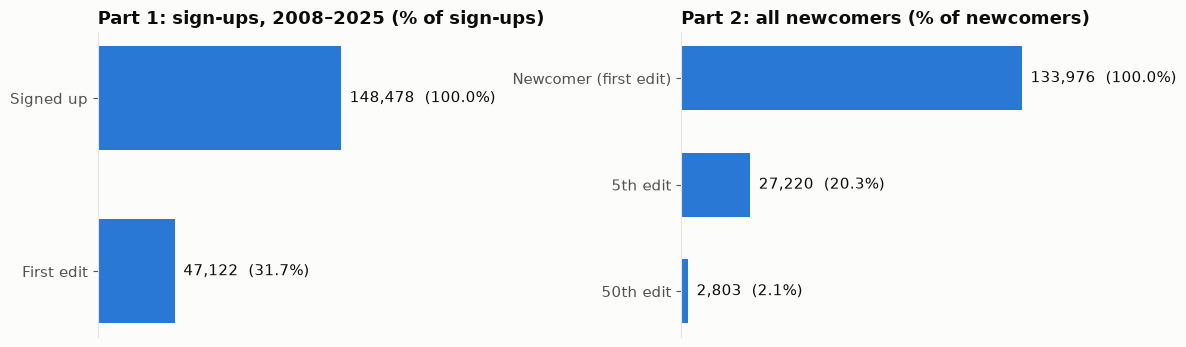

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})


def funnel_bars(ax, labels, counts, title):
    y = np.arange(len(labels))[::-1]  # first step at the top
    ax.barh(y, counts, color=BLUE, height=0.6)
    for yy, n, share in zip(y, counts, 100 * np.array(counts) / counts[0]):
        ax.annotate(f"{n:,}  ({share:.1f}%)", (n, yy), xytext=(6, 0), textcoords="offset points", va="center",
                    color=TEXT)
    ax.set_yticks(y, labels=labels)
    ax.set_xlim(0, counts[0] * 1.45)
    ax.set_xticks([])  # every bar carries its own number, so the x-axis isn't needed
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title)
    ax.grid(False)


funnel_bars(left, ["Signed up", "First edit"], list(funnel["count"][:2]), "Part 1: sign-ups, 2008–2025 (% of sign-ups)")
funnel_bars(right, ["Newcomer (first edit)", "5th edit", "50th edit"],
            [len(newcomers), funnel.loc[2, "count"], funnel.loc[3, "count"]], "Part 2: all newcomers (% of newcomers)")
plt.tight_layout()
plt.show()

**The whole path for people who signed up here.** Following only accounts created by a person through all four
steps gives one chain from sign-up to 50th edit.

In [4]:
signup_chain = signups.merge(newcomers[["user_id", "fifth_edit", "fiftieth_edit"]], on="user_id", how="left")
# Sign-ups who never became newcomers have no match: .eq(True) turns those empty values into False
signup_chain[["fifth_edit", "fiftieth_edit"]] = signup_chain[["fifth_edit", "fiftieth_edit"]].eq(True)
chain = pd.Series({
    "Signed up": len(signup_chain),
    "First edit within 180 days": signup_chain["first_edit"].sum(),
    "... and 5th edit within 180 days of it": (signup_chain["first_edit"] & signup_chain["fifth_edit"]).sum(),
    "... and 50th edit within 180 days of it": (signup_chain["first_edit"] & signup_chain["fiftieth_edit"]).sum(),
}, name="accounts").to_frame()
chain["per_1000_signups"] = 1000 * chain["accounts"] / len(signup_chain)
chain.round(1)

,accounts,per_1000_signups
Signed up,148478,1000.0
First edit within 180 days,47122,317.4
... and 5th edit within 180 days of it,10035,67.6
... and 50th edit within 180 days of it,921,6.2


## 2. When the first edit comes

For sign-ups, the time between creating the account and the first human edit.

In [5]:
limits = {"within 1 hour": 1, "within 1 day": 24, "within 7 days": 24 * 7, "within 30 days": 24 * 30,
          "within 180 days": 24 * 180, "ever (any time)": np.inf}
hours = signups["hours_to_first_edit"]
timing = pd.DataFrame({
    "accounts": {name: int((hours < limit).sum()) for name, limit in limits.items()},
})
timing["pct_of_signups"] = 100 * timing["accounts"] / len(signups)
timing["pct_of_those_who_ever_edit"] = 100 * timing["accounts"] / hours.notna().sum()
timing.round(1)

,accounts,pct_of_signups,pct_of_those_who_ever_edit
within 1 hour,41873,28.2,88.4
within 1 day,44539,30.0,94.0
within 7 days,45844,30.9,96.8
within 30 days,46612,31.4,98.4
within 180 days,47122,31.7,99.5
ever (any time),47361,31.9,100.0


## 3. Over the years

Each step's conversion rate, by year: sign-up → first edit by the year the account was created, and the later steps
by cohort year (the year of the first edit). The three charts have their own y-axes because the rates are on very
different scales. The shaded band is the 95% confidence interval.

In [6]:
by_year_signups = signups.groupby("created_year").agg(signups=("first_edit", "size"), first_edit=("first_edit", "sum"))
by_year_newcomers = newcomers.groupby("cohort_year").agg(
    newcomers=("fifth_edit", "size"), fifth_edit=("fifth_edit", "sum"), fiftieth_edit=("fiftieth_edit", "sum"))

by_year = by_year_signups.join(by_year_newcomers)
by_year["signup_to_first_pct"], by_year["signup_to_first_ci"] = pct_with_ci(by_year["first_edit"], by_year["signups"])
by_year["newcomer_to_5th_pct"], by_year["newcomer_to_5th_ci"] = pct_with_ci(by_year["fifth_edit"], by_year["newcomers"])
by_year["5th_to_50th_pct"], by_year["5th_to_50th_ci"] = pct_with_ci(by_year["fiftieth_edit"], by_year["fifth_edit"])
by_year.index.name = "year"
by_year[["signups", "first_edit", "signup_to_first_pct", "newcomers", "fifth_edit", "newcomer_to_5th_pct",
         "fiftieth_edit", "5th_to_50th_pct"]].round(1)

,signups,first_edit,signup_to_first_pct,newcomers,fifth_edit,newcomer_to_5th_pct,fiftieth_edit,5th_to_50th_pct
year,,,,,,,,
2008,8378,2867,34.2,5534,1491,26.9,196,13.1
2009,9277,2605,28.1,7579,1551,20.5,149,9.6
2010,6530,1943,29.8,6755,1259,18.6,130,10.3
2011,5946,1583,26.6,5831,1058,18.1,98,9.3
2012,6540,1793,27.4,5856,1249,21.3,125,10.0
2013,7133,1593,22.3,5251,955,18.2,119,12.5
2014,7457,1806,24.2,5130,851,16.6,93,10.9
2015,6990,1985,28.4,5634,985,17.5,66,6.7
2016,8032,2107,26.2,5768,886,15.4,78,8.8


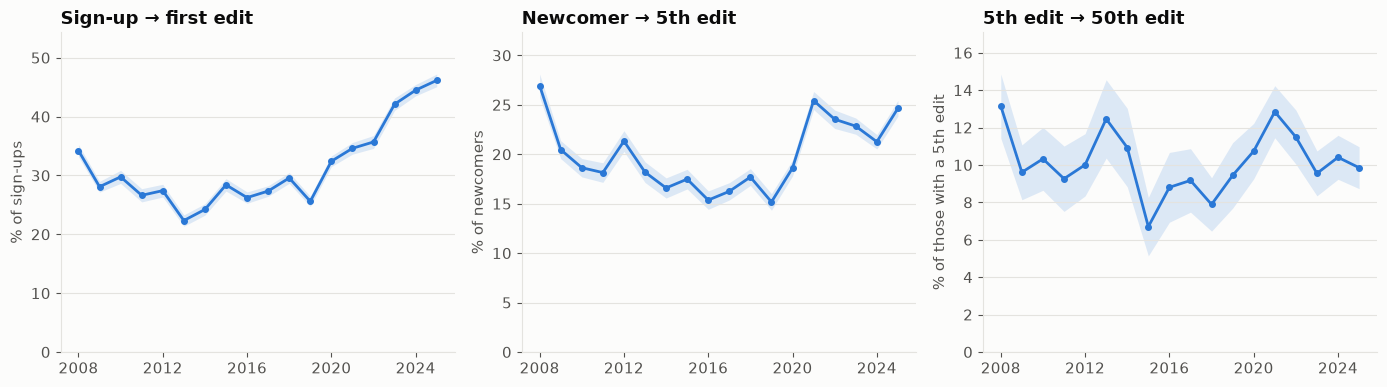

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [
    ("signup_to_first", "Sign-up → first edit", "% of sign-ups"),
    ("newcomer_to_5th", "Newcomer → 5th edit", "% of newcomers"),
    ("5th_to_50th", "5th edit → 50th edit", "% of those with a 5th edit"),
]
for ax, (name, title, ylabel) in zip(axes, panels):
    rate, ci = by_year[f"{name}_pct"], by_year[f"{name}_ci"]
    ax.fill_between(by_year.index, rate - ci, rate + ci, color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(by_year.index, rate, color=BLUE, linewidth=2, marker="o", markersize=4)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, (rate + ci).max() * 1.15)
    ax.set_xticks(range(2008, 2026, 4))
plt.tight_layout()
plt.show()

## 4. By creation method

Part 2 of the funnel for newcomers whose account was created in each way. Part 1 only exists for sign-ups.

In [8]:
by_method = newcomers.groupby("created_by").agg(
    newcomers=("fifth_edit", "size"), fifth_edit=("fifth_edit", "sum"), fiftieth_edit=("fiftieth_edit", "sum"))
by_method["newcomer_to_5th_pct"], by_method["newcomer_to_5th_ci"] = pct_with_ci(by_method["fifth_edit"], by_method["newcomers"])
by_method["5th_to_50th_pct"], by_method["5th_to_50th_ci"] = pct_with_ci(by_method["fiftieth_edit"], by_method["fifth_edit"])
by_method["newcomer_to_50th_pct"] = 100 * by_method["fiftieth_edit"] / by_method["newcomers"]
by_method.sort_values("newcomers", ascending=False).round(1)

,newcomers,fifth_edit,fiftieth_edit,newcomer_to_5th_pct,newcomer_to_5th_ci,5th_to_50th_pct,5th_to_50th_ci,newcomer_to_50th_pct
created_by,,,,,,,,
created automatically,82611,16284,1787,19.7,0.3,11.0,0.5,2.2
signed up here (self or another user),47425,10113,934,21.3,0.4,9.2,0.6,2.0
unknown,3940,823,82,20.9,1.3,10.0,2.0,2.1


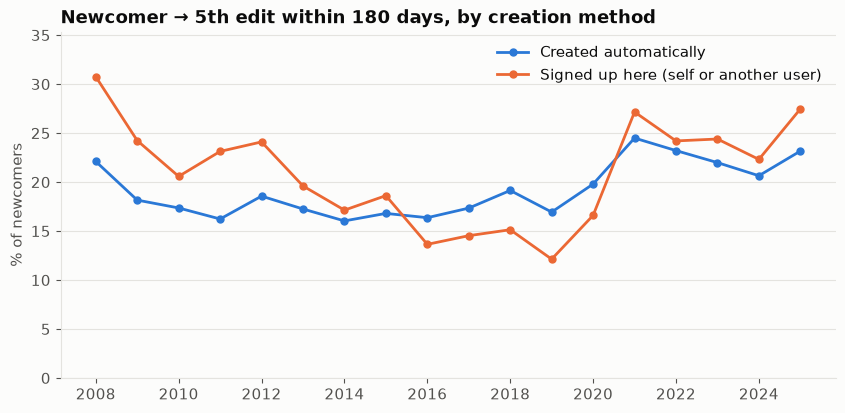

In [9]:
method_by_year = (newcomers[newcomers["created_by"] != "unknown"]
                  .groupby(["cohort_year", "created_by"])["fifth_edit"].mean().unstack() * 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
for column, color in [("created automatically", BLUE), ("signed up here (self or another user)", ORANGE)]:
    ax.plot(method_by_year.index, method_by_year[column], color=color, linewidth=2, marker="o", markersize=5,
            label=column.capitalize())
ax.set_title("Newcomer → 5th edit within 180 days, by creation method")
ax.set_ylabel("% of newcomers")
ax.set_ylim(0, method_by_year.values.max() * 1.15)
ax.set_xticks(range(2008, 2026, 2))
ax.legend(frameon=False, loc="upper right")
plt.show()

## Findings

**1. Most of the funnel is lost before the first edit.** Of every 1,000 people who sign up, 317 make a first edit
within 180 days, 68 reach a 5th edit and 6 a 50th. 68% of sign-ups never edit at all.

**2. The first edit comes right away or not at all.** 88% of sign-ups who ever edit make their first edit within an
hour of creating the account, and 94% within a day. Only 239 of 148,478 sign-ups made a first edit after 180 days.
The first hour after sign-up is when a newcomer can be reached.

**3. Far more sign-ups have made a first edit in recent years.** The share was 22–30% in 2013–2019, 32–36% in
2020–2022 and 42–46% in 2023–2025, with about as many sign-ups a year as before (7,344–10,222 since 2017).
Where sign-ups make their first edit didn't change (74–80% in articles every year since 2017), so it isn't a new
kind of edit. The data doesn't show why; changes to the wiki's sign-up and newcomer pages in those years would be
the place to look.

**4. Reaching a 5th edit follows the retention trend.** 26.9% of the 2008 newcomers reached a 5th edit within 180
days, 15–18% in 2013–2019 and 21–25% in 2021–2025. The 2021 rise matches the rise in retention in notebook 01.

**5. About one in ten newcomers with a 5th edit reaches a 50th (10.3%).** Between years it ranges from 6.7% to 13.1%,
with wide intervals and no clear trend.

**6. Sign-ups get going as often as automatic accounts, but don't stay.** Newcomers who signed up here reach a 5th
edit about as often as those with an automatic account (21.3% vs. 19.7%; 22–27% vs. 21–25% a year since 2021),
and a 50th about as often (2.0% vs. 2.2%). Yet in 2021–2025 they were retained in months 3–6 at 2.4–4.4%, against
6.5–8.2% for automatic accounts. Many sign-ups make a burst of edits and then leave, so a fast start alone doesn't
show that someone will stay.